# TP1 — Comptage de mots : quatre méthodes
## Partie 2/2 : PySpark

**Date :** 13/10/2026 · **Nom :** Battiste Boungo · **Identifiant :** 04 ·
**Cours :** Fondements et Application de Big Data (5A)

Suite de la [partie 1](../Partie1_Python_MapReduce_Hadoop/notebook_comptage_mots.ipynb) (Python séquentiel,
pseudo-MapReduce, Hadoop MapReduce) : la **4e méthode, PySpark**, implémentée de quatre façons (RDD + `reduceByKey`,
RDD + `groupByKey`, DataFrame, Spark SQL) et comparée aux trois premières sur les mêmes fichiers.

*Note : ce notebook a été écrit comme une séance séparée ; dans la suite, « TP1 » désigne la partie 1 (Python et
Hadoop) et les mesures Hadoop reprises de cette partie.*

Notebook exécuté de bout en bout, sans erreur.

### Comptage de mots avec Apache Spark (PySpark)

**Cours :** Fondements et Application de Big Data

**Consigne :** on reprend le comptage de mots du TP1, mais avec **Apache Spark**, depuis **PySpark**.

Ce notebook :
1. présente le modèle d'exécution de Spark et ce qui le distingue de Hadoop MapReduce ;
2. implémente le comptage de mots de **quatre façons** : RDD + `reduceByKey`, RDD + `groupByKey`, DataFrame, Spark SQL ;
3. teste ces implémentations (résultats identiques à Python et à `collections.Counter`) ;
4. compare les performances sur **les mêmes fichiers que le TP1** (N = 10 000 lignes dupliquées m fois, de 10 000 à 20 millions de lignes),
   avec Python simple, pseudo-MapReduce et Hadoop MapReduce, ainsi que la **scalabilité** de Spark en nombre de cœurs ;
5. conclut sur l'intérêt de Spark.

Partie 1 : [`../Partie1_Python_MapReduce_Hadoop`](../Partie1_Python_MapReduce_Hadoop)

## 0. Environnement d'exécution

**PySpark tourne dans un conteneur Linux (Docker)**, construit à partir du `Dockerfile` du projet
(Python 3.12, OpenJDK 17, PySpark 4.2.0). Le notebook lui-même est exécuté dans ce conteneur.

Pourquoi pas directement sous Windows ? PySpark s'y installe (`pip install pyspark`) et fonctionne, mais lors de la mise en place
nous avons mesuré un coût prohibitif : **sous Windows, Spark ne peut pas `fork`er un démon Python** et lance un nouvel interpréteur
pour chaque tâche. Sur ce poste (Python du Microsoft Store), cela donnait :

| Mesure (session Spark déjà démarrée, `local[*]`) | Windows natif | Conteneur Linux |
|---|---:|---:|
| job vide de 8 tâches (`parallelize(range(8), 8).count()`) | 40 à 62 s | 0,37 s |
| comptage RDD `reduceByKey`, 1 M de lignes | 57 à 73 s | ≈ 5 s |
| comptage DataFrame, 1 M de lignes (2ᵉ exécution) | 1,6 s | ≈ 2 à 5 s |

Le DataFrame n'est presque pas pénalisé sous Windows car il s'exécute **entièrement dans la JVM**, sans worker Python —
une première illustration de la différence entre les deux API.

Lancer le projet :
```bash
docker build -t spark-wordcount:4.2.0 .
docker run --rm -p 8888:8888 -v "%cd%:/work" spark-wordcount:4.2.0 jupyter lab --ip=0.0.0.0 --allow-root --no-browser
docker run --rm -v "%cd%:/work" spark-wordcount:4.2.0 python src/benchmark_spark.py      # benchmark complet
docker run --rm -v "%cd%:/work" spark-wordcount:4.2.0 python -m pytest -v tests          # tests
```

In [1]:
import os, sys, platform, subprocess, time
sys.path.insert(0, os.path.abspath("src"))
import pyspark, psutil
print("OS      :", platform.platform())
print("Python  :", sys.version.split()[0])
print("PySpark :", pyspark.__version__)
print("Java    :", subprocess.run(["java", "-version"], capture_output=True, text=True).stderr.splitlines()[0])
print("CPU     :", os.cpu_count(), "cœurs visibles,", round(psutil.virtual_memory().total / 1e9, 1), "Go de RAM")

OS      : Linux-5.15.167.4-microsoft-standard-WSL2-x86_64-with-glibc2.36
Python  : 3.12.15
PySpark : 4.2.0


Java    : openjdk version "17.0.20.1" 2026-08-18
CPU     : 8 cœurs visibles, 8.2 Go de RAM


## 1. Spark en bref, et la différence avec Hadoop MapReduce

| | Hadoop MapReduce (TP1) | Apache Spark |
|---|---|---|
| Modèle | exactement 2 phases : map puis reduce | un **DAG** quelconque de transformations (`map`, `filter`, `join`, `reduceByKey`…) |
| Données intermédiaires | écrites sur **disque** (et HDFS) entre chaque job | gardées **en mémoire** quand c'est possible, disque seulement au *shuffle* |
| Exécution | un job = des JVM lancées par YARN pour chaque tâche | des **executors** qui restent vivants pendant toute l'application |
| API | Java (ou Streaming via stdin/stdout) | Scala, Java, **Python (PySpark)**, R, SQL |
| Optimisation | aucune : on écrit le plan à la main | DataFrame/SQL : optimiseur **Catalyst** + génération de code (*Tungsten*) |

Vocabulaire :
- **driver** : le programme principal (ici le noyau Python + une JVM pilotée par `py4j`), qui construit le plan ;
- **executors** : les processus qui exécutent les **tâches** — une tâche par **partition** de données. En mode `local[k]`, driver et executor sont dans
  la même JVM avec *k* threads : on simule un petit cluster sur une machine ;
- **transformations** (`flatMap`, `map`, `reduceByKey`, `groupBy`…) : **paresseuses**, elles ne font que construire le plan ;
- **actions** (`collect`, `count`, `save…`) : déclenchent réellement le calcul ;
- **shuffle** : redistribution des données par clé entre partitions (l'équivalent du *shuffle & sort* de MapReduce) ; il découpe le job en **stages**.

Le comptage de mots en Spark est donc le même algorithme que le TP1 — *map* `(mot, 1)` puis *reduce* par clé — mais exprimé en quelques lignes
et exécuté sans relancer de JVM ni écrire sur HDFS.

## 2. Fichiers de test

On réutilise **exactement le générateur du TP1** (`src/generer_fichier.py`, même graine) : N = 10 000 lignes d'un mot
(40 mots, distribution de Zipf), puis duplication m fois. Les fichiers sont écrits dans `/tmp/data`, sur le disque du conteneur
(lire à travers le montage Windows est beaucoup plus lent et fausserait les mesures).

In [2]:
import generer_fichier, wordcount_simple, wordcount_mapreduce
N, DATA = 10_000, "/tmp/data"
os.makedirs(DATA, exist_ok=True)
base = generer_fichier.generer_base(f"{DATA}/mots_N{N}.txt", N)
FICHIERS = {m: generer_fichier.dupliquer(base, f"{DATA}/mots_N{N}_m{m}.txt", m) for m in [1, 10, 100]}
for m, f in FICHIERS.items():
    print(f"m = {m:>3} : {N*m:>9} lignes, {os.path.getsize(f)/1e6:6.2f} Mo")
REF = wordcount_simple.compter_occurrences(FICHIERS[100])     # résultat de référence (méthode 1 du TP1)

m =   1 :     10000 lignes,   0.06 Mo
m =  10 :    100000 lignes,   0.61 Mo
m = 100 :   1000000 lignes,   6.11 Mo


## 3. Démarrer Spark

`src/spark_wordcount.py` contient les quatre implémentations et la création de la session :
- `master("local[*]")` : un executor local avec autant de threads que de cœurs ;
- `spark.sql.shuffle.partitions = 8` au lieu de 200 par défaut (200 partitions pour ~40 mots distincts n'aurait aucun sens) ;
- `spark.driver.memory = 4g`.

In [3]:
print(open("src/spark_wordcount.py", encoding="utf-8").read())

"""Comptage de mots avec Apache Spark (PySpark) : quatre implémentations.

  1. rdd_reduce   : API RDD, flatMap -> map -> reduceByKey   (agrégation locale avant le shuffle, comme un combiner)
  2. rdd_group    : API RDD, flatMap -> map -> groupByKey -> somme (pas d'agrégation locale : comme le pseudo-MapReduce)
  3. dataframe    : API DataFrame, split -> explode -> groupBy().count()  (optimiseur Catalyst, exécution dans la JVM)
  4. sql          : même requête écrite en Spark SQL

Usage :
    python src/spark_wordcount.py data/mots_N10000_m100.txt --methode dataframe --master "local[*]"
"""
import argparse
import os
import sys
import time

# Sous Windows, Spark lance des workers Python : on lui indique l'interpréteur courant.
os.environ.setdefault("PYSPARK_PYTHON", sys.executable)
os.environ.setdefault("PYSPARK_DRIVER_PYTHON", sys.executable)
# Spark 4 exige Java 17 ou 21 : on utilise le JDK 17 s'il est installé à l'emplacement standard.
_JDK17 = r"C:\Program Files\Java\jdk-17"
if "JAV

In [4]:
import spark_wordcount
t0 = time.perf_counter()
spark = spark_wordcount.creer_session("local[*]", nom="notebook")
sc = spark.sparkContext
print(f"SparkSession créée en {time.perf_counter() - t0:.1f} s — Spark {spark.version}, master {sc.master}, "
      f"parallélisme par défaut : {sc.defaultParallelism}")

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/10/13 14:58:41 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


SparkSession créée en 36.3 s — Spark 4.2.0, master local[*], parallélisme par défaut : 8


Ce temps de démarrage (lancement de la JVM, chargement de centaines de classes, création du contexte) n'est payé **qu'une fois** par application :
contrairement à Hadoop MapReduce, les jobs suivants réutilisent les mêmes executors.

## 4. Méthode A — RDD + `reduceByKey`

C'est la traduction directe du WordCount MapReduce :

```python
sc.textFile(f)                       # RDD de lignes, découpé en partitions
  .flatMap(lambda l: l.split())      # map : une ligne -> plusieurs mots
  .map(lambda mot: (mot, 1))         # map : mot -> (mot, 1)
  .reduceByKey(lambda a, b: a + b)   # shuffle + reduce par clé
  .collect()                         # action : rapatrie le résultat au driver
```

`reduceByKey` **agrège d'abord localement dans chaque partition** (*map-side combine*, exactement le rôle du *combiner* du WordCount Java d'Hadoop),
puis n'envoie au shuffle qu'une paire par mot et par partition.

> *Les temps affichés dans les démonstrations des §§ 4 à 7 sont ceux des **premières** exécutions de la session : ils incluent la chauffe (compilation JIT de la JVM, démarrage des workers Python, génération de code). Les temps de référence, mesurés après chauffe, sont au § 9.*

In [5]:
lignes = sc.textFile(FICHIERS[100], minPartitions=sc.defaultParallelism)
comptes = lignes.flatMap(lambda l: l.split()).map(lambda mot: (mot, 1)).reduceByKey(lambda a, b: a + b)
print("Partitions en entrée :", lignes.getNumPartitions())
print("Rien n'a encore été calculé : les transformations sont paresseuses. Lignage du RDD :")
print(comptes.toDebugString().decode())

Partitions en entrée : 8
Rien n'a encore été calculé : les transformations sont paresseuses. Lignage du RDD :
(8) PythonRDD[6] at RDD at PythonRDD.scala:59 []
 |  MapPartitionsRDD[5] at mapPartitions at PythonRDD.scala:197 []
 |  ShuffledRDD[4] at partitionBy at NativeMethodAccessorImpl.java:0 []
 +-(8) PairwiseRDD[3] at reduceByKey at /tmp/ipykernel_7/3463237511.py:2 []
    |  PythonRDD[2] at reduceByKey at /tmp/ipykernel_7/3463237511.py:2 []
    |  /tmp/data/mots_N10000_m100.txt MapPartitionsRDD[1] at textFile at NativeMethodAccessorImpl.java:0 []
    |  /tmp/data/mots_N10000_m100.txt HadoopRDD[0] at textFile at NativeMethodAccessorImpl.java:0 []


In [6]:
t0 = time.perf_counter()
resultat = dict(comptes.collect())                     # action -> exécution du DAG (2 stages séparés par le shuffle)
print(f"collect() : {time.perf_counter() - t0:.2f} s")
print(sorted(resultat.items(), key=lambda x: -x[1])[:8])
print("Identique à la méthode 1 du TP1 :", resultat == REF)

collect() : 17.90 s
[('chat', 232500), ('chien', 117700), ('arbre', 78000), ('fleur', 56600), ('maison', 45600), ('soleil', 38700), ('montagne', 33300), ('livre', 29300)]
Identique à la méthode 1 du TP1 : True


## 5. Méthode B — RDD + `groupByKey`

Même chose, mais en regroupant d'abord toutes les valeurs par clé puis en les sommant : c'est exactement la structure du
**pseudo-MapReduce** du TP1 (`shuffle` qui construit `mot -> [1, 1, 1, …]`, puis `reducer`). Sans agrégation locale, **chaque paire
`(mot, 1)` traverse le shuffle** : la documentation de Spark recommande d'éviter `groupByKey` pour une agrégation.

In [7]:
groupes = sc.textFile(FICHIERS[100], minPartitions=sc.defaultParallelism) \
            .flatMap(lambda l: l.split()).map(lambda mot: (mot, 1)).groupByKey().mapValues(sum)
t0 = time.perf_counter()
resultat_b = dict(groupes.collect())
print(f"collect() : {time.perf_counter() - t0:.2f} s — identique :", resultat_b == REF)

collect() : 6.87 s — identique : True


## 6. Méthode C — DataFrame

On décrit le calcul de façon **déclarative** avec des fonctions Spark SQL ; aucune fonction Python n'est exécutée sur les données :
tout se passe dans la JVM, avec du code généré par Spark.

```python
spark.read.text(f)                                         # DataFrame à une colonne "value"
     .select(F.explode(F.split("value", r"\s+")).alias("mot"))
     .where(F.col("mot") != "")
     .groupBy("mot").count()
```

Le plan physique produit par Catalyst montre deux `HashAggregate` : une agrégation **partielle** dans chaque partition (`partial_count`,
l'équivalent du combiner), un `Exchange` (le shuffle), puis l'agrégation **finale**.

In [8]:
from pyspark.sql import functions as F
mots = spark.read.text(FICHIERS[100]).select(F.explode(F.split(F.col("value"), r"\s+")).alias("mot")).where(F.col("mot") != "")
compte_df = mots.groupBy("mot").count()
compte_df.explain()

== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- HashAggregate(keys=[mot#2], functions=[count(1)])
   +- Exchange hashpartitioning(mot#2, 8), ENSURE_REQUIREMENTS, [plan_id=19]
      +- HashAggregate(keys=[mot#2], functions=[partial_count(1)])
         +- Filter NOT (mot#2 = )
            +- Generate explode(split(value#0, \s+, -1)), false, [mot#2]
               +- FileScan text [value#0] Batched: false, DataFilters: [], Format: Text, Location: InMemoryFileIndex(1 paths)[file:/tmp/data/mots_N10000_m100.txt], PartitionFilters: [], PushedFilters: [], ReadSchema: struct<value:string>




In [9]:
t0 = time.perf_counter()
compte_df.orderBy(F.desc("count")).show(8)
print(f"{time.perf_counter() - t0:.2f} s — identique :",
      {r["mot"]: r["count"] for r in compte_df.collect()} == REF)

+--------+------+
|     mot| count|
+--------+------+
|    chat|232500|
|   chien|117700|
|   arbre| 78000|
|   fleur| 56600|
|  maison| 45600|
|  soleil| 38700|
|montagne| 33300|
|    ciel| 29300|
+--------+------+
only showing top 8 rows


18.57 s — identique : True


## 7. Méthode D — Spark SQL

Exactement la même requête, écrite en SQL sur une vue temporaire. Catalyst produit **le même plan** que pour le DataFrame :
les deux API sont équivalentes en performance.

In [10]:
spark.read.text(FICHIERS[100]).createOrReplaceTempView("lignes")
requete = r'''
    SELECT mot, COUNT(*) AS nb
    FROM (SELECT explode(split(value, '\\s+')) AS mot FROM lignes)
    WHERE mot <> ''
    GROUP BY mot
    ORDER BY nb DESC
'''
spark.sql(requete).show(8)
print("identique :", {r["mot"]: r["nb"] for r in spark.sql(requete).collect()} == REF)

+--------+------+
|     mot|    nb|
+--------+------+
|    chat|232500|
|   chien|117700|
|   arbre| 78000|
|   fleur| 56600|
|  maison| 45600|
|  soleil| 38700|
|montagne| 33300|
|    ciel| 29300|
+--------+------+
only showing top 8 rows


identique : True


## 8. Tests

`tests/test_spark_wordcount.py` (pytest, session Spark `local[2]` partagée), pour **chacune des 4 méthodes** :
- un petit exemple vérifié à la main ;
- des lignes « sales » : plusieurs mots par ligne, espaces multiples, tabulations, lignes vides ;
- le fichier vide ;
- l'égalité avec `collections.Counter`, la méthode 1 et la méthode 2 du TP1 sur 100 000 lignes générées ;

et le partitionnement minimal du RDD. Le benchmark revérifie en plus, à **chaque taille de fichier**, que chaque méthode Spark donne
exactement le résultat de la méthode 1.

In [11]:
spark.stop()   # les tests créent leur propre session
r = subprocess.run([sys.executable, "-m", "pytest", "-v", "--color=no", "-p", "no:cacheprovider", "tests"],
                   capture_output=True, text=True)
print(r.stdout[-3500:])

============================= test session starts ==============================
platform linux -- Python 3.12.15, pytest-9.1.1, pluggy-1.6.0 -- /usr/local/bin/python3.12
rootdir: /work
plugins: anyio-4.15.1, platformdirs-4.13.0
collecting ... collected 17 items

tests/test_spark_wordcount.py::test_petit_exemple[rdd_reduce] PASSED     [  5%]
tests/test_spark_wordcount.py::test_petit_exemple[rdd_group] PASSED      [ 11%]
tests/test_spark_wordcount.py::test_petit_exemple[dataframe] PASSED      [ 17%]
tests/test_spark_wordcount.py::test_petit_exemple[sql] PASSED            [ 23%]
tests/test_spark_wordcount.py::test_espaces_et_lignes_vides[rdd_reduce] PASSED [ 29%]
tests/test_spark_wordcount.py::test_espaces_et_lignes_vides[rdd_group] PASSED [ 35%]
tests/test_spark_wordcount.py::test_espaces_et_lignes_vides[dataframe] PASSED [ 41%]
tests/test_spark_wordcount.py::test_espaces_et_lignes_vides[sql] PASSED  [ 47%]
tests/test_spark_wordcount.py::test_fichier_vide[rdd_reduce] PASSED      [ 52%]


## 9. Comparaison des performances

### 9.1 Protocole

`src/benchmark_spark.py` (exécuté dans le conteneur) mesure, sur m ∈ {1, 10, 100, 500, 1000, 2000} :

1. **temps « chaud »** : chaque méthode Spark dans une session `local[*]` déjà démarrée et chauffée (médiane de 3) — le temps d'un job dans
   une application Spark en cours ; plus Python simple et pseudo-MapReduce dans le **même conteneur** (processus complet, médiane de 3, comme au TP1) ;
2. **temps « à froid »** : `python src/spark_wordcount.py fichier` dans un nouveau processus — démarrage de la JVM et de la session compris,
   comparable au `time python …` et au job Hadoop du TP1 ;
3. **scalabilité** : le fichier de 5 M de lignes avec `local[1]`, `local[2]`, `local[4]`, `local[8]`.

Les temps Hadoop sont ceux du TP1 (cluster pseudo-distribué dans Docker, sur la même machine).

*Contexte des mesures :* le poste n'était pas au repos (visioconférence et enregistrement vidéo en cours, autres conteneurs Docker actifs) :
les temps absolus sont bruités, mais toutes les méthodes du TP2 ont été mesurées dans les mêmes conditions.

In [12]:
import pandas as pd
chaud = pd.read_csv("results/temps_chaud.csv")
froid = pd.read_csv("results/temps_froid.csv")
scal = pd.read_csv("results/scalabilite.csv")
hadoop = pd.read_csv("results/tp1/benchmark_hadoop.csv")

ORDRE = ["python_simple", "pseudo_mapreduce", "spark_rdd_reduce", "spark_rdd_group", "spark_dataframe", "spark_sql"]
tab = chaud.pivot(index=["m", "lignes", "taille_mo"], columns="methode", values="temps_s")[ORDRE]
tab["hadoop_java (TP1)"] = hadoop[hadoop.methode == "hadoop_java"].set_index("m")["temps_s"].values
tab.round(3)

,,methode,python_simple,pseudo_mapreduce,spark_rdd_reduce,spark_rdd_group,spark_dataframe,spark_sql,hadoop_java (TP1)
m,lignes,taille_mo,,,,,,,
1,10000,0.061,0.382,0.417,1.885,1.320,1.474,1.322,69.846
10,100000,0.611,0.376,1.052,4.656,2.254,2.936,2.511,69.413
100,1000000,6.108,4.461,5.244,5.127,4.233,1.454,3.175,82.271
500,5000000,30.541,10.893,29.193,21.698,22.356,9.665,6.150,103.458
1000,10000000,61.082,16.930,70.849,41.157,41.081,7.914,7.582,102.292
2000,20000000,122.164,15.848,59.855,62.101,63.388,12.625,13.204,156.595


In [13]:
f = froid.pivot(index=["m", "lignes"], columns="methode", values="temps_total_s")
f.columns = [c + " (à froid)" for c in f.columns]
f["hadoop_java (TP1)"] = hadoop[hadoop.methode == "hadoop_java"].set_index("m")["temps_s"].values
f["python_simple"] = chaud[chaud.methode == "python_simple"].set_index("m")["temps_s"].values
f.round(2)

,,spark_dataframe (à froid),spark_rdd_reduce (à froid),hadoop_java (TP1),python_simple
m,lignes,,,,
1,10000,37.71,35.76,69.85,0.38
10,100000,36.72,30.24,69.41,0.38
100,1000000,34.61,34.16,82.27,4.46
500,5000000,41.60,61.02,103.46,10.89
1000,10000000,88.33,72.71,102.29,16.93
2000,20000000,132.85,156.68,156.59,15.85


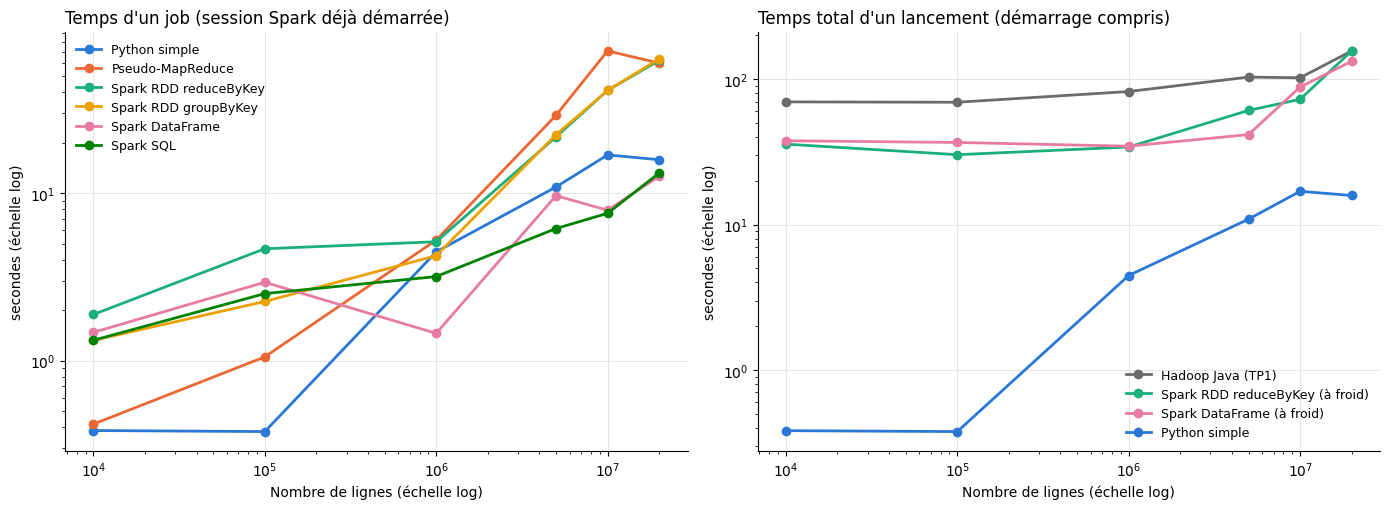

In [14]:
import matplotlib.pyplot as plt
COUL = {"python_simple": "#2a78d6", "pseudo_mapreduce": "#eb6834", "spark_rdd_reduce": "#1baf7a",
        "spark_rdd_group": "#eda100", "spark_dataframe": "#e87ba4", "spark_sql": "#008300", "hadoop_java": "#6b6b6b"}
NOMS = {"python_simple": "Python simple", "pseudo_mapreduce": "Pseudo-MapReduce", "spark_rdd_reduce": "Spark RDD reduceByKey",
        "spark_rdd_group": "Spark RDD groupByKey", "spark_dataframe": "Spark DataFrame", "spark_sql": "Spark SQL",
        "hadoop_java": "Hadoop Java (TP1)"}

def style(ax, titre):
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("Nombre de lignes (échelle log)"); ax.set_ylabel("secondes (échelle log)")
    ax.set_title(titre, loc="left", fontsize=12)
    ax.grid(True, which="major", color="#e5e5e5", linewidth=0.8)
    for s in ("top", "right"): ax.spines[s].set_visible(False)
    ax.legend(frameon=False, fontsize=9)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
for meth in ORDRE:
    g = chaud[chaud.methode == meth].sort_values("lignes")
    axes[0].plot(g.lignes, g.temps_s, marker="o", ms=6, lw=2, color=COUL[meth], label=NOMS[meth])
style(axes[0], "Temps d'un job (session Spark déjà démarrée)")

g = hadoop[hadoop.methode == "hadoop_java"].sort_values("lignes")
axes[1].plot(g.lignes, g.temps_s, marker="o", ms=6, lw=2, color=COUL["hadoop_java"], label=NOMS["hadoop_java"])
for meth in ["spark_rdd_reduce", "spark_dataframe"]:
    g = froid[froid.methode == meth].sort_values("lignes")
    axes[1].plot(g.lignes, g.temps_total_s, marker="o", ms=6, lw=2, color=COUL[meth], label=NOMS[meth] + " (à froid)")
g = chaud[chaud.methode == "python_simple"].sort_values("lignes")
axes[1].plot(g.lignes, g.temps_s, marker="o", ms=6, lw=2, color=COUL["python_simple"], label=NOMS["python_simple"])
style(axes[1], "Temps total d'un lancement (démarrage compris)")
plt.tight_layout(); plt.savefig("results/comparaison.png", dpi=130); plt.show()

In [15]:
s = scal.pivot(index="coeurs", columns="methode", values="temps_s")
for c in list(s.columns):
    s[c.replace("spark_", "accélération ")] = (s[c].iloc[0] / s[c]).round(2)
print(f"Fichier : {scal.lignes.iloc[0]:,} lignes ({scal.taille_mo.iloc[0]} Mo)".replace(",", " "))
s.round(3)

Fichier : 5 000 000 lignes (30.541 Mo)


methode,spark_dataframe,spark_rdd_reduce,accélération dataframe,accélération rdd_reduce
coeurs,,,,
1,19.484,103.320,1.00,1.00
2,14.545,49.392,1.34,2.09
4,12.316,29.502,1.58,3.50
8,7.530,21.340,2.59,4.84


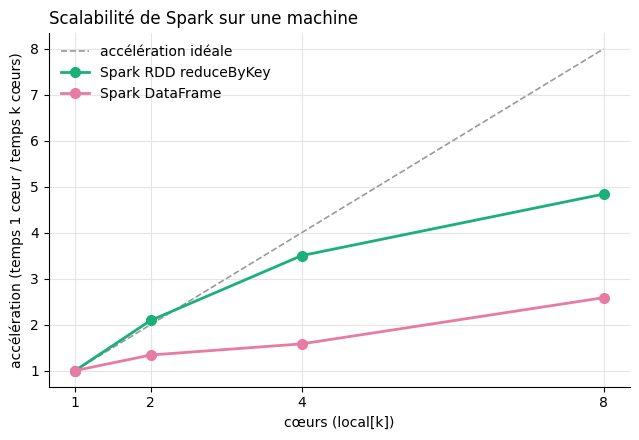

In [16]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
k = sorted(scal.coeurs.unique())
ax.plot(k, k, ls="--", lw=1.2, color="#9a9a9a", label="accélération idéale")
for meth in ["spark_rdd_reduce", "spark_dataframe"]:
    g = scal[scal.methode == meth].sort_values("coeurs")
    ax.plot(g.coeurs, g.temps_s.iloc[0] / g.temps_s, marker="o", ms=7, lw=2, color=COUL[meth], label=NOMS[meth])
ax.set_xticks(k); ax.set_xlabel("cœurs (local[k])"); ax.set_ylabel("accélération (temps 1 cœur / temps k cœurs)")
ax.set_title("Scalabilité de Spark sur une machine", loc="left", fontsize=12)
ax.grid(True, color="#e5e5e5", linewidth=0.8)
for sp in ("top", "right"): ax.spines[sp].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout(); plt.savefig("results/scalabilite.png", dpi=130); plt.show()

### 9.2 Analyse

**Petits fichiers (≤ 100 000 lignes) : Spark est plus lent que Python.** Même avec une session déjà démarrée, un job Spark coûte
au minimum ≈ 1,3 à 4,7 s contre 0,4 s pour Python simple (3 à 12 fois plus) : planification du DAG, lancement de 8 tâches,
aller-retour driver ↔ JVM via `py4j`, shuffle et `collect`. Sur des données aussi petites, il n'y a rien à paralléliser
et ce coût fixe domine.

**Gros fichiers : l'API DataFrame / SQL dépasse Python.** Dès 1 M de lignes, DataFrame et SQL sont **plus rapides que Python simple**,
et l'écart se creuse avec la taille : sur 10 M de lignes, ≈ 7,6 à 7,9 s contre 16,9 s, soit **≈ 2 fois plus rapide**.
Spark découpe le fichier en partitions traitées en parallèle sur les 8 cœurs, et le calcul se fait dans la JVM, avec du code généré
et une agrégation partielle par partition (les deux `HashAggregate` du plan) : seules ≈ 40 lignes par partition traversent le shuffle.
DataFrame et SQL ont le même plan physique et des temps équivalents, aux fluctuations de mesure près.

**L'API RDD en Python est pénalisée.** Les deux versions RDD sont **2 à 4 fois plus lentes que Python simple** sur les gros fichiers
(≈ 41 s pour 10 M de lignes, ≈ 62 s pour 20 M). Chaque ligne est sérialisée (pickle) de la JVM vers un worker Python, traitée par
nos `lambda`, puis les paires sont renvoyées à la JVM : ce coût de sérialisation dépasse le gain du parallélisme. C'est la
leçon principale de PySpark : **préférer les DataFrames** (fonctions natives de Spark) aux RDD avec des fonctions Python, qui ne
sont utiles que lorsque la transformation ne s'exprime pas autrement.

**`reduceByKey` vs `groupByKey`.** Aucune différence mesurable ici : avec seulement ≈ 40 mots distincts, le temps est dominé
par le passage des données dans les workers Python (côté map), pas par le shuffle. Sur des données à très nombreuses clés distinctes,
`groupByKey` matérialiserait toutes les valeurs de chaque clé et transférerait toutes les paires, d'où la recommandation de
toujours préférer `reduceByKey` pour une agrégation. À structure égale, `groupByKey` reste plus rapide que le pseudo-MapReduce du TP1
(41 s contre 71 s pour 10 M de lignes) et, surtout, il n'a pas besoin de tout garder en mémoire (≈ 2,6 Go au TP1 pour 20 M de lignes) :
Spark déborde sur disque si nécessaire.

**Démarrage à froid : la moitié de la latence de Hadoop.** Un lancement complet (`python src/spark_wordcount.py fichier`)
coûte ≈ **30 à 38 s** pour les petits fichiers, essentiellement le démarrage de la JVM et de la SparkSession, contre ≈ **70 s** pour un job
Hadoop MapReduce sur la même machine (TP1). Spark ne paie ce coût **qu'une fois par application** : les jobs suivants réutilisent
les mêmes executors (temps « chauds » ci-dessus), alors que Hadoop relance des JVM via YARN pour **chaque** job. Pour un traitement
en plusieurs étapes, ou interactif comme dans ce notebook, c'est un avantage décisif.

**Scalabilité.** Sur le fichier de 5 M de lignes, passer de 1 à 8 cœurs accélère la version RDD de **×4,8** (103 s → 21 s) et la version
DataFrame de **×2,6** (19,5 s → 7,5 s). La version RDD, limitée par le CPU des workers Python, profite bien des cœurs supplémentaires.
La version DataFrame est déjà rapide sur un cœur, donc la part fixe (lecture du fichier, planification, collecte) pèse davantage.
Aucune n'atteint l'accélération idéale ×8 : les 8 cœurs logiques correspondent à 4 cœurs physiques (hyperthreading), et la machine
était partagée avec d'autres programmes pendant les mesures. Sur un vrai cluster, le même code s'exécuterait sans modification sur
plusieurs machines (`--master yarn` ou `spark://…`) : seule la valeur du *master* change.

**Fiabilité des mesures.** Le poste n'était pas au repos (CPU hôte à 95–100 %) : certains temps fluctuent, par exemple Python simple
mesuré à 15,8 s pour 20 M de lignes mais 16,9 s pour 10 M (13,3 s pour 20 M au TP1, sur une machine au repos). Les ordres de grandeur
et le classement des méthodes sont nets et reproductibles ; les valeurs absolues sont à ± 30 % environ.

| Méthode | Petits fichiers | Gros fichiers (≥ 1 M lignes) | Mémoire / passage à l'échelle |
|---|---|---|---|
| Python simple (TP1) | le plus rapide | rapide mais 1 seul cœur | tout en RAM, une machine |
| Pseudo-MapReduce (TP1) | rapide | 3–4× plus lent que Python | tout en RAM (2,6 Go pour 20 M lignes) |
| Hadoop MapReduce (TP1) | ≈ 70 s par job | ≈ 100–160 s | disque, cluster, mais latence élevée à chaque job |
| Spark RDD (PySpark) | 1–5 s par job | 2–4× plus lent que Python | parallèle, déborde sur disque ; pénalisé par la sérialisation Python |
| **Spark DataFrame / SQL** | 1–3 s par job | **jusqu'à ≈ 2× plus rapide que Python** | parallèle, optimisé (Catalyst), même code sur un cluster |

## 10. Conclusion

- Les quatre implémentations Spark donnent **exactement le même résultat** que Python et Hadoop (tests + vérification à chaque taille).
- Spark exprime le comptage de mots en **quelques lignes**, avec le même schéma *map → shuffle → reduce* qu'au TP1, et réutilise
  ses executors d'un job à l'autre : la latence par job tombe de ≈ 70 s (Hadoop) à ≈ 1–5 s une fois la session démarrée, et le démarrage
  à froid (≈ 30–38 s) est environ deux fois plus court que celui d'un job Hadoop.
- Sur une seule machine, **l'API DataFrame/SQL est la meilleure option dès le million de lignes** (jusqu'à ≈ 2× plus rapide que Python pur),
  grâce au parallélisme sur les cœurs et à l'optimiseur Catalyst, alors que **l'API RDD avec des lambdas Python est pénalisée** par la
  sérialisation JVM ↔ Python.
- Pour de petits fichiers, Python reste imbattable : Spark, comme Hadoop, est conçu pour des volumes qui justifient sa mise en route.
- Par rapport à Hadoop MapReduce, Spark garde les données en mémoire entre les étapes, offre des API de haut niveau (DataFrame, SQL)
  et passe à l'échelle d'un cluster sans changer le code : c'est aujourd'hui l'outil de référence pour ce type de traitement.